# 04 · The same pipeline, in LangChain

Part 1 built every piece by hand. From here on we use **LangChain**, the most widely used
framework for LLM applications. You now know what each LangChain class does underneath, so none
of it should feel like magic.

**In this notebook you will:**
- map each hand-written step from notebooks 01–03 to its LangChain equivalent,
- build the full index of the Token Hotels corpus with LangChain loaders and splitters,
- compose a RAG chain with **LCEL** (LangChain Expression Language) and run it stage by stage,
- harden the prompt so the model refuses instead of guessing,
- return the retrieved sources along with the answer (needed for evaluation next).

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: build (or reuse) the baseline index used by notebooks 04-08
from raglab.bootstrap import ensure_index

store = ensure_index("nb04_baseline")

[nb04_baseline] reusing index (109 chunks)


In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

## 1. Hand-written → LangChain

| Step | Part 1 (by hand) | LangChain |
|---|---|---|
| Document type | `Document` (borrowed) | `langchain_core.documents.Document` |
| Load PDF / Markdown / HTML / CSV | `loaders.load_pdf` … | `PyPDFLoader`, `TextLoader`, `BSHTMLLoader`, `CSVLoader` |
| Recursive chunking | `chunking.chunk_recursive` | `RecursiveCharacterTextSplitter` |
| Header-aware chunking | `chunking.chunk_markdown_headers` | `MarkdownHeaderTextSplitter`, `HTMLHeaderTextSplitter` |
| Embeddings | `llm.embed` | an `Embeddings` class (ours wraps `llm.embed`, so the cache still works) |
| Vector store | raw `chromadb` | `langchain_chroma.Chroma` |
| Top-k search | `store_chroma.query` | `store.as_retriever(search_kwargs={"k": 4})` |
| Prompt | f-string in `scratch.build_prompt` | `ChatPromptTemplate` |
| Chat call | `llm.chat` | `ChatOpenAI` (ours: `llm.get_lc_chat()`) |
| The loop | `scratch.answer` | an **LCEL chain** |

`raglab.chunking.chunk_corpus_lc` picks a splitter per file type: header-aware for Markdown and HTML,
recursive for PDF and CSV. The setup cell above used it to build the index.

In [4]:
from collections import Counter

from raglab.bootstrap import get_chunks

chunks = get_chunks("nb04_baseline")
print(f"{len(chunks)} chunks")
Counter(c.metadata["source_file"] for c in chunks)

109 chunks

Counter({'room_rates.csv': 48,
         'hotel_profiles.pdf': 12,
         'dining_guide.md': 10,
         'faq.html': 9,
         'guest_reviews.md': 9,
         'loyalty_program.md': 6,
         'loyalty_program_reprint.md': 6,
         'cancellation_policy_2025.md': 5,
         'cancellation_policy_2024.md': 4})

Notice the HTML FAQ: `HTMLHeaderTextSplitter` cut it at every `<h2>` and recorded the heading
as `section`, something our hand-written loader in notebook 02 couldn't do:

In [5]:
from raglab.display import show_chunks

faq_chunks = [c for c in chunks if c.metadata["source_file"] == "faq.html"]
show_chunks([c for c in faq_chunks if "section" in c.metadata], n=2, width=200)

7 chunk(s), showing 2

[1] source_file=faq.html | doc_type=faq | section=Reservations and check-in | page_title=Token Hotels & Resorts — Frequently Asked Questions  (489 chars)
    Early check-in depends on availability on the day. To guarantee a room from 9:00 AM, book the Early
    Arrival add-on for $50. Can I check in early? Late checkout until 2:00 PM costs $40 and must be …

[2] source_file=faq.html | doc_type=faq | section=Wi-Fi and connectivity | page_title=Token Hotels & Resorts — Frequently Asked Questions  (160 chars)
    Yes. Wi-Fi is free for every guest at every Token Hotels & Resorts property. The network name and
    password are printed on your key card sleeve. Is Wi-Fi free?


But look at the very first FAQ chunk. The navigation bar became a chunk of its own, and the
splitter can't know it's boilerplate:

In [6]:
show_chunks(faq_chunks[:1])

1 chunk(s)

[1] source_file=faq.html | doc_type=faq  (40 chars)
    · · · Home Hotels Offers Sign in


## 2. A retriever

A **retriever** is anything that takes a question and returns Documents. The simplest one comes
straight from the vector store:

In [7]:
retriever = store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
docs = retriever.invoke("What time is check-in at Token Kyoto?")
show_chunks(docs, n=4, width=120)

4 chunk(s)

[1] source_file=hotel_profiles.pdf | page=0 | doc_type=profile | hotel_name=Token Kyoto  (556 chars)
    Token Kyoto — profile Check-in at Token Kyoto starts at 4:00 PM and check-out is at 11:00 AM. The
    hotel has 64 rooms, a …

[2] source_file=room_rates.csv | doc_type=rates | hotel_name=Token Kyoto  (118 chars)
    Token Kyoto — rates hotel: Token Kyoto city: Kyoto room_type: Suite season: high nightly_rate_usd:
    1485 max_guests: 4

[3] source_file=room_rates.csv | doc_type=rates | hotel_name=Token Kyoto  (117 chars)
    Token Kyoto — rates hotel: Token Kyoto city: Kyoto room_type: Suite season: low nightly_rate_usd:
    1145 max_guests: 4

[4] source_file=room_rates.csv | doc_type=rates | hotel_name=Token Kyoto  (117 chars)
    Token Kyoto — rates hotel: Token Kyoto city: Kyoto room_type: Deluxe season: low nightly_rate_usd:
    730 max_guests: 3


## 3. The chain, one stage at a time

LCEL chains are built with the `|` operator: the output of one step is the input of the next.
Here is the RAG chain from `raglab.chains.build_rag_chain`:

```python
chain = (
    {"context": retriever | RunnableLambda(format_docs), "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)
```

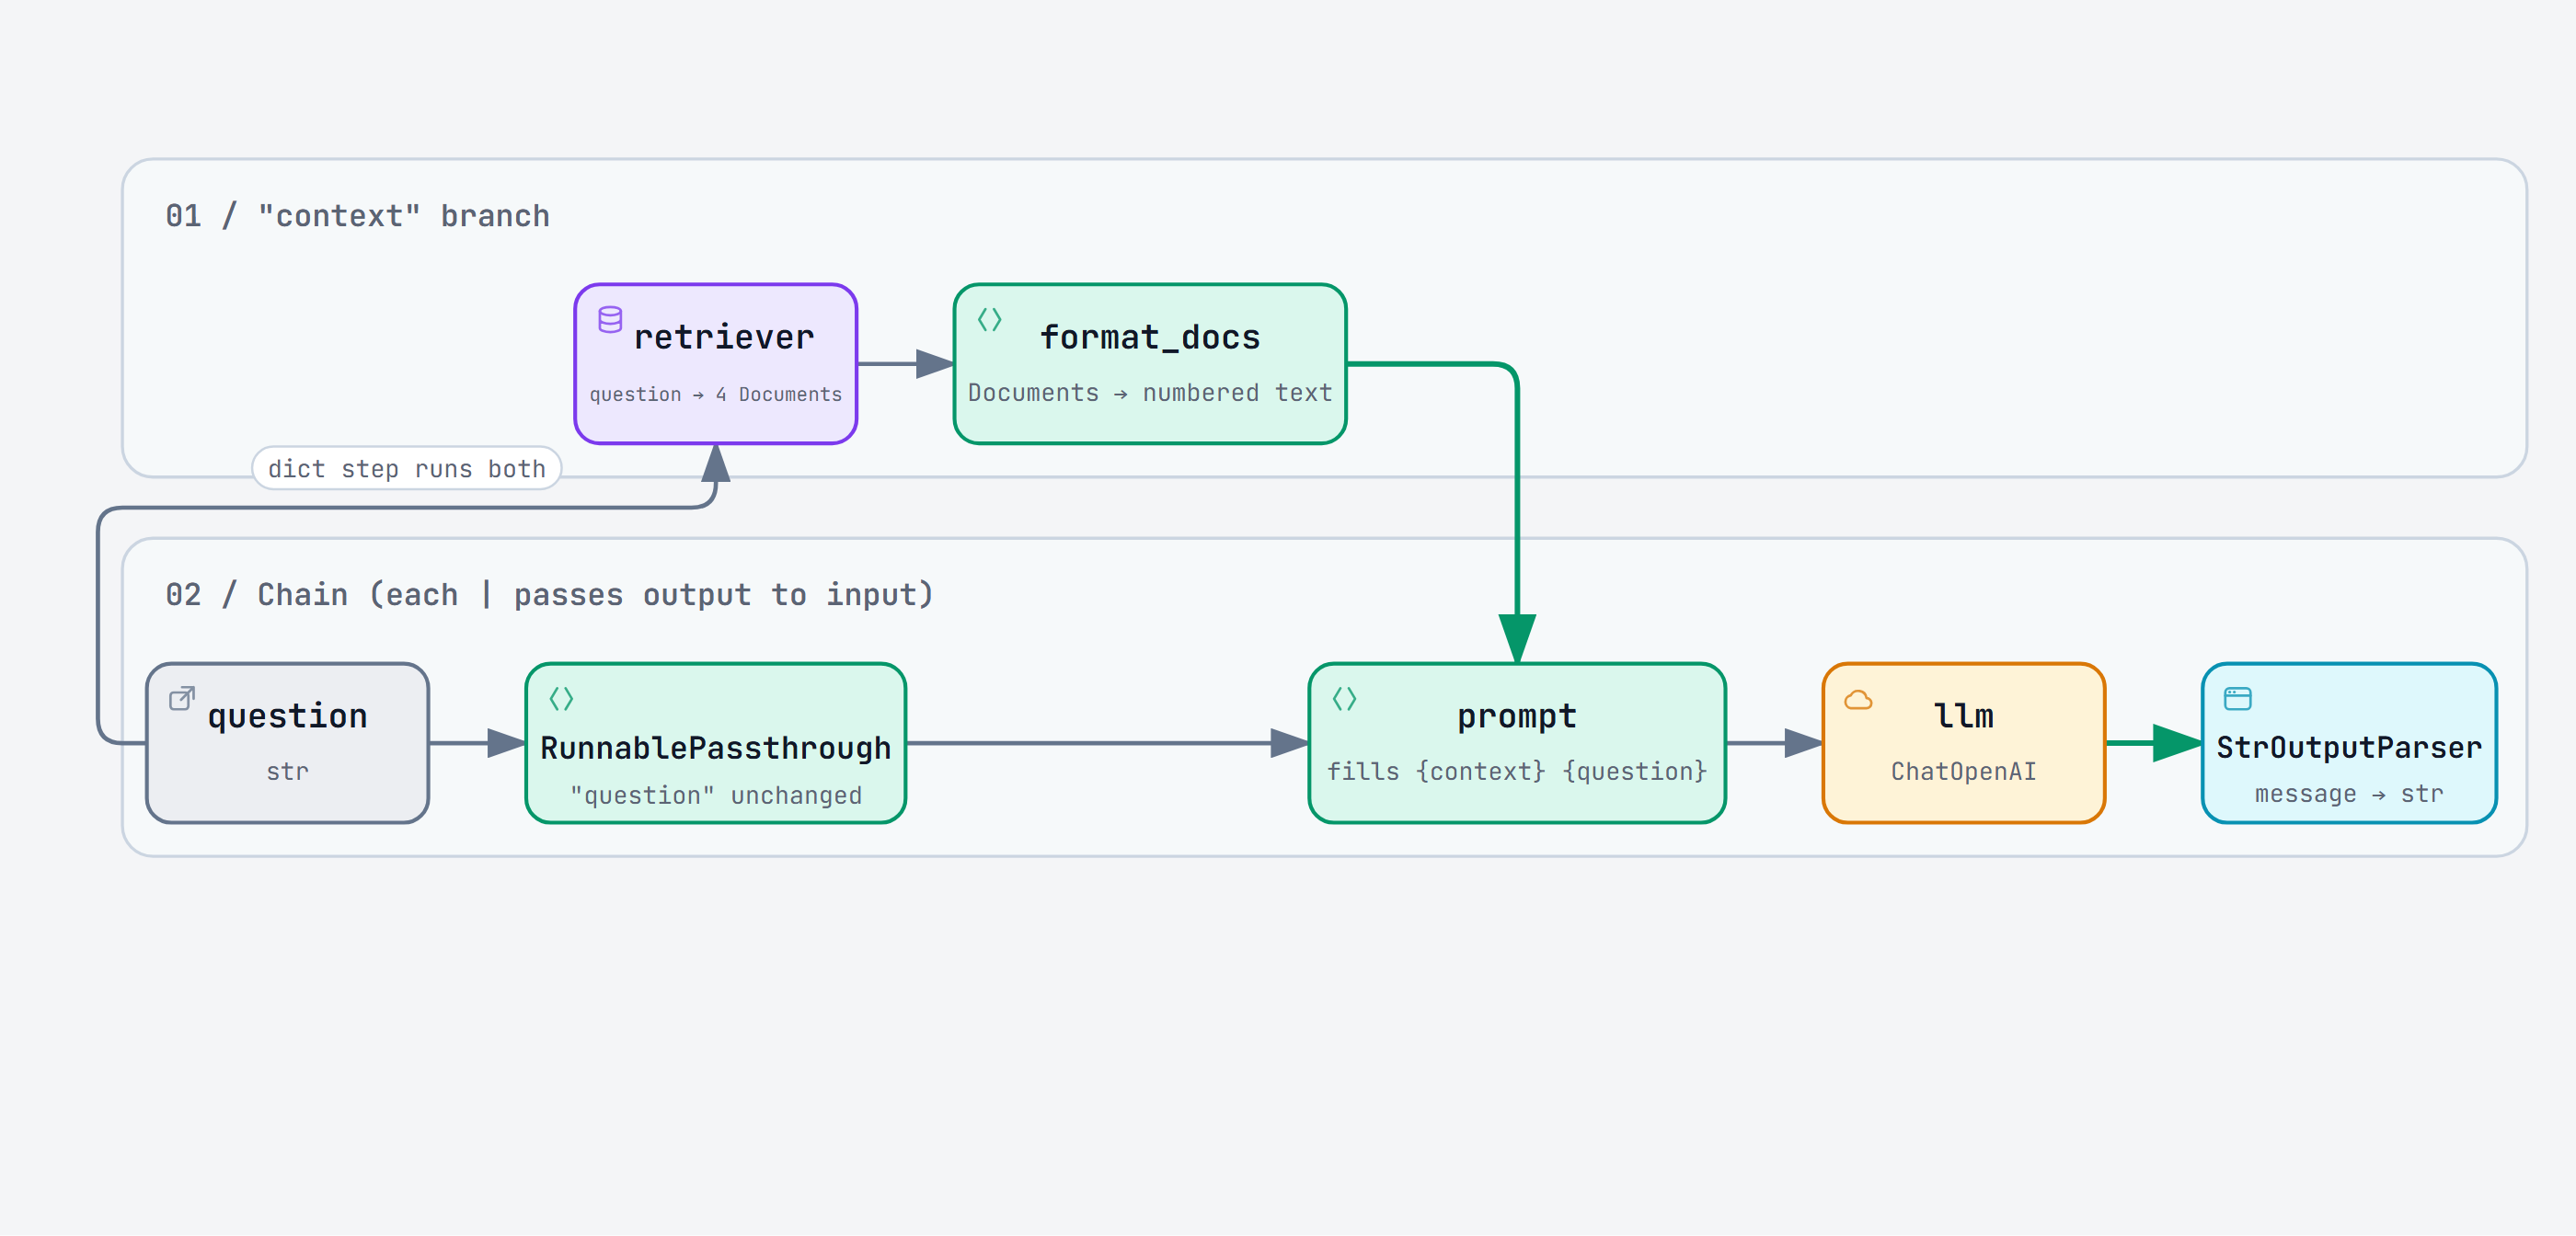

[Open interactive version](../diagrams/lcel_chain.html)

In [8]:
from raglab.display import show_diagram

show_diagram("lcel_chain")

Let's run each stage by hand to see what flows between them.

**Stage 1, the dict step:** runs the retriever and the passthrough *in parallel* on the same input.

In [9]:
from langchain_core.runnables import RunnableLambda, RunnablePassthrough

from raglab import chains

question = "What time is check-in at Token Kyoto?"
step1 = {"context": retriever | RunnableLambda(chains.format_docs), "question": RunnablePassthrough()}
from langchain_core.runnables import RunnableParallel

inputs = RunnableParallel(step1).invoke(question)
print("keys:", list(inputs))
print(inputs["context"][:500], "…")

keys: ['context', 'question']
[1] (hotel_profiles.pdf) Token Kyoto — profile

Check-in at Token Kyoto starts at 4:00 PM and check-out is at 11:00 AM. The hotel has 64 rooms, and rates at
Token Kyoto start from $520 per night. Token Kyoto does not have a swimming pool. The hotel also has a private
onsen-style spa fed by mineral water. A private car from Kansai Airport costs $180 one way and must be booked
48 hours ahead.
Feature Token Kyoto
Location Kyoto, Japan (Asia)
Star rating 5 stars
Rooms 64
Swimming pool No
Spa Yes
Che …


**Stage 2, the prompt:** fills `{context}` and `{question}` and produces chat messages.

In [10]:
messages = chains.GROUNDED_PROMPT.invoke(inputs)
for m in messages.to_messages():
    print(f"--- {m.type} ---\n{m.content[:400]}\n")

--- system ---
You are the guest concierge for Token Hotels & Resorts. Answer using ONLY the numbered context passages. Never use outside knowledge, and never guess. If the passages do not contain the answer, reply with exactly: "I couldn't find that in the Token Hotels documents." Keep answers short and factual. If two passages disagree, prefer the most recent one and say so.

--- human ---
Context:
[1] (hotel_profiles.pdf) Token Kyoto — profile

Check-in at Token Kyoto starts at 4:00 PM and check-out is at 11:00 AM. The hotel has 64 rooms, and rates at
Token Kyoto start from $520 per night. Token Kyoto does not have a swimming pool. The hotel also has a private
onsen-style spa fed by mineral water. A private car from Kansai Airport costs $180 one way and must be booked
48 hours ahea



**Stages 3 and 4, the model and the parser:** the model returns a message object, and the parser
pulls out its text.

In [11]:
from langchain_core.output_parsers import StrOutputParser

from raglab.llm import get_lc_chat

llm = get_lc_chat()
message = llm.invoke(messages)
print(type(message).__name__, "→", StrOutputParser().invoke(message))

AIMessage → Check-in at Token Kyoto starts at 4:00 PM.


And the whole chain in one call:

In [12]:
rag = chains.build_rag_chain(retriever)
rag.invoke(question)

'Check-in at Token Kyoto starts at 4:00 PM.'

## 4. Prompts matter: basic vs grounded

`chains.BASIC_PROMPT` just says "use the context". `chains.GROUNDED_PROMPT` adds a role, forbids
outside knowledge, tells the model to prefer the most recent document when two disagree, and
gives it an **exact sentence** to use when the answer isn't there.

In [13]:
print(chains.GROUNDED_PROMPT.messages[0].prompt.template)

You are the guest concierge for Token Hotels & Resorts. Answer using ONLY the numbered context passages. Never use outside knowledge, and never guess. If the passages do not contain the answer, reply with exactly: "I couldn't find that in the Token Hotels documents." Keep answers short and factual. If two passages disagree, prefer the most recent one and say so.


In [14]:
basic = chains.build_rag_chain(retriever, chains.BASIC_PROMPT)
grounded = chains.build_rag_chain(retriever, chains.GROUNDED_PROMPT)

for q in [
    "How many hours before arrival can I cancel for free?",  # two policy versions disagree
    "Does Token Kyoto have a gym?",  # not in the documents
    "Who is the general manager of Token Lisbon?",  # not in the documents
]:
    print(f"Q: {q}\n  basic:    {basic.invoke(q)}\n  grounded: {grounded.invoke(q)}\n")

Q: How many hours before arrival can I cancel for free?
  basic:    For a Flexible-rate booking, you can cancel for free up to 72 hours before arrival.
  grounded: For a Flexible rate, you can cancel free of charge up to 72 hours before arrival.



Q: Does Token Kyoto have a gym?
  basic:    The provided information doesn’t say whether Token Kyoto has a gym.
  grounded: I couldn't find that in the Token Hotels documents.



Q: Who is the general manager of Token Lisbon?
  basic:    The context does not specify the general manager of Token Lisbon.
  grounded: I couldn't find that in the Token Hotels documents.



Read the answers closely (the run saved in this notebook is shown above; yours may word things differently):

- **Refusals.** Modern models often refuse sensibly even with a basic prompt, but in their own
  words. The grounded prompt makes the refusal an *exact, known sentence* (`chains.NOT_FOUND`),
  so code can detect it: show a fallback, log the gap, and count refusals in evaluation.
- **Conflicting versions.** Whether the answer is 48 hours (2024 policy) or 72 hours (2025 policy)
  depends on which policy chunks were retrieved, and on whether the prompt says how to resolve
  conflicts. Notebook 09 fixes this properly with version metadata.

## 5. Return the sources too

For evaluation (next notebook) and citations (notebook 10) we need the retrieved chunks *as well
as* the answer. `build_rag_chain_with_sources` retrieves once and returns both:

In [15]:
rag_with_sources = chains.build_rag_chain_with_sources(retriever)
result = rag_with_sources.invoke("Can I bring my dog to Token Lisbon?")
print(result["answer"])
print("\nsources:", [d.metadata["source_file"] for d in result["contexts"]])

Yes. Dogs under 10 kg are welcome at Token Lisbon for a fee of $30 per night.

sources: ['faq.html', 'hotel_profiles.pdf', 'dining_guide.md', 'hotel_profiles.pdf']


## Your turn

1. Write a prompt that answers in bullet points and ends every bullet with its source in
   brackets, e.g. `[faq.html]`. Build a chain with it and ask about pets and parking.
2. Change the retriever to `k=1`. Which of the questions above break?
3. Use `search_type="mmr"` in `as_retriever` (LangChain's built-in MMR) and compare the sources
   returned for "What is Token Marrakech like?" with plain similarity.

<details><summary>A starting point for 1</summary>

```python
from langchain_core.prompts import ChatPromptTemplate
bullets = ChatPromptTemplate.from_messages([
    ("system", "Answer only from the numbered context passages, as short bullet points. "
               "End each bullet with the source file of the passage it came from in [brackets]. "
               f'If the answer is not there, reply exactly: "{chains.NOT_FOUND}"'),
    ("human", "Context:\n{context}\n\nQuestion: {question}"),
])
chains.build_rag_chain(retriever, bullets).invoke("Can I bring my dog, and is there parking?")
```
</details>

## Key takeaways

- LangChain packages the same steps you wrote by hand: loaders, splitters, vector store, retriever, prompt, model.
- LCEL composes them with `|`; a dict step runs branches in parallel on the same input.
- A grounded prompt with an exact refusal sentence makes behaviour predictable and measurable.
- Return the contexts with the answer; evaluation and citations depend on them.

**Added to raglab:** `llm.CachedEmbeddings / get_lc_chat`, `loaders.load_corpus_lc`,
`chunking.chunk_corpus_lc`, `store_chroma.create_lc_store / load_lc_store`,
`bootstrap.ensure_index / get_chunks`, `chains.NOT_FOUND / format_docs / BASIC_PROMPT /
GROUNDED_PROMPT / build_rag_chain / build_rag_chain_with_sources`.

In [16]:
cost.report()

model                       calls   in tokens  out tokens       USD
gpt-6-luna                      9       4,142         157    0.0005
total                           9                            0.0005
